# 03 - Comparison Models: Random Forest vs XGBoost


In [19]:
import sys
!{sys.executable} -m pip install optuna xgboost lightgbm shap imbalanced-learn scikit-learn pandas numpy matplotlib seaborn joblib

In [20]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import config as cfg
from src.preprocess          import load_and_prepare, scale
from src.feature_engineering import engineer_features
from src.preprocess          import split_engineered
from src.train               import (train_rf, train_xgb,
                                     tune_threshold, save_model)
from src.evaluate            import (get_metrics, plot_cm, plot_roc,
                                     plot_threshold_curve,
                                     plot_feature_importance,
                                     comparison_table, print_report)
import json
print('All imports OK')

All imports OK


In [21]:
#Load and prepare base data
data = load_and_prepare()
X_train = data['X_train']
X_val   = data['X_val']
X_test  = data['X_test']
y_train = data['y_train']
y_val   = data['y_val']
y_test  = data['y_test']
spw     = data['spw']
df      = data['df']

# Also get scaled version for LR comparison
X_train_s, X_val_s, X_test_s, scaler = scale(X_train, X_val, X_test)

# Load LR results saved in notebook 02
try:
    lr_results = json.loads((cfg.OUT_DIR / 'lr_results.json').read_text())
    print('LR results loaded from notebook 02')
except FileNotFoundError:
    print('Run 02_BaselineModel.ipynb first to generate lr_results.json')
    lr_results = {'Model': 'Logistic Regression',
                  'Accuracy': 0, 'Precision': 0, 'Recall': 0,
                  'F1': 0, 'ROC-AUC': 0}

[load_raw] Loaded 101,371 rows × 16 cols
[clean] Dropped 5,062 pre-season rows → 96,309 remain
[clean] Filled 66 nulls in Compound with 'UNKNOWN'
[encode] Added OHE columns: ['C_HARD', 'C_INTERMEDIATE', 'C_MEDIUM', 'C_SOFT', 'C_UNKNOWN', 'C_WET']
[encode] Added Driver_Freq, Compound_Ordinal
[split] Train  :  44,117 rows  | pit rate = 0.157
[split] Val    :  26,381 rows  | pit rate = 0.343
[split] Test   :  25,811 rows  | pit rate = 0.332
[class_weight] neg=37,178 pos=6,939 → scale_pos_weight=5.358
[scale] StandardScaler fitted on train, applied to val + test
LR results loaded from notebook 02


In [22]:
#Random Forest
rf_model = train_rf(X_train, y_train)

rf_probs = rf_model.predict_proba(X_val)[:, 1]
rf_thresh, _ = tune_threshold(rf_model, X_val, y_val)
rf_preds = (rf_probs >= rf_thresh).astype(int)

rf_results = get_metrics('Random Forest', y_val, rf_preds, rf_probs)
print(pd.Series(rf_results))

[train_rf] Random Forest fitted. params={'n_estimators': 200, 'max_depth': 10, 'class_weight': 'balanced', 'random_state': 42, 'n_jobs': -1}
[tune_threshold] Best threshold=0.44  Best F1=0.6607
Model        Random Forest
Accuracy            0.7135
Precision           0.5567
Recall              0.8126
F1                  0.6607
ROC-AUC             0.7969
dtype: object



  Random Forest — Classification Report
              precision    recall  f1-score   support

      No Pit       0.87      0.66      0.75     17326
         Pit       0.56      0.81      0.66      9055

    accuracy                           0.71     26381
   macro avg       0.71      0.74      0.71     26381
weighted avg       0.76      0.71      0.72     26381



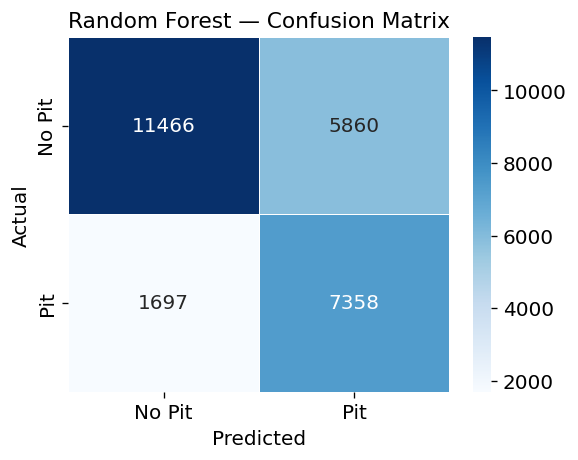

In [23]:
print_report('Random Forest', y_val, rf_preds)
plot_cm(y_val, rf_preds, 'Random Forest', fname='rf_confusion_matrix.png')

In [24]:
#XGBoost
print(f'scale_pos_weight = {spw:.3f}  (neg/pos ratio)')

xgb_model = train_xgb(X_train, y_train, X_val, y_val, spw)

xgb_probs = xgb_model.predict_proba(X_val)[:, 1]
xgb_thresh, _ = tune_threshold(xgb_model, X_val, y_val)
xgb_preds = (xgb_probs >= xgb_thresh).astype(int)

xgb_results = get_metrics('XGBoost (base)', y_val, xgb_preds, xgb_probs)
print(pd.Series(xgb_results))

scale_pos_weight = 5.358  (neg/pos ratio)
[train_xgb] XGBoost fitted. n_estimators=300
[tune_threshold] Best threshold=0.40  Best F1=0.6661
Model        XGBoost (base)
Accuracy             0.7268
Precision            0.5738
Recall               0.7939
F1                   0.6661
ROC-AUC               0.816
dtype: object



  XGBoost (base) — Classification Report
              precision    recall  f1-score   support

      No Pit       0.87      0.69      0.77     17326
         Pit       0.57      0.79      0.67      9055

    accuracy                           0.73     26381
   macro avg       0.72      0.74      0.72     26381
weighted avg       0.77      0.73      0.73     26381



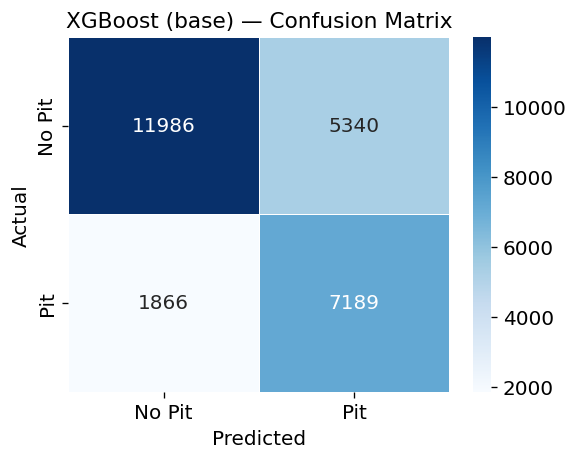

TypeError: plot_feature_importance() got an unexpected keyword argument 'fname'

In [25]:
print_report('XGBoost (base)', y_val, xgb_preds)
plot_cm(y_val, xgb_preds, 'XGBoost (base)', fname='xgb_base_confusion_matrix.png')
plot_feature_importance(xgb_model, cfg.BASE_FEATURES, fname='xgb_base_feature_imp.png')

In [ ]:
df_eng = engineer_features(df)
df_eng.head(3)

[engineer_features] Added 7 features: ['LapTime_Roll3', 'LapTime_Accel', 'LapsSinceLastPit', 'RacePhase', 'TyreLife_x_Compound', 'Position_Roll3', 'DegRate_Roll3']


,Driver,LapNumber,Compound,Stint,TyreLife,Position,LapTime (s),Race,Year,LapTime_Delta,...,C_WET,Driver_Freq,Compound_Ordinal,LapTime_Roll3,LapTime_Accel,LapsSinceLastPit,RacePhase,TyreLife_x_Compound,Position_Roll3,DegRate_Roll3
79511,ALB,1,HARD,1,1.0,20,101.690,Australian Grand Prix,2022,-3.333,...,0,0.04632,2.0,101.6900,0.000,0,0.0,2.0,20.0,0.000
79512,ALB,2,HARD,1,2.0,19,89.169,Australian Grand Prix,2022,-9.960,...,0,0.04632,2.0,95.4295,-6.627,1,0.0,4.0,19.5,35.176
79513,ALB,3,HARD,1,3.0,18,115.834,Australian Grand Prix,2022,17.974,...,0,0.04632,2.0,102.2310,27.934,2,0.0,6.0,19.0,26.614


In [ ]:
print('New features added:')
for f in cfg.ENG_FEATURES:
    non_null = df_eng[f].notna().sum()
    print(f'  {f:<25} | non-null: {non_null:,} | mean: {df_eng[f].mean():.3f}')

New features added:
  LapTime_Roll3             | non-null: 96,309 | mean: 92.781
  LapTime_Accel             | non-null: 96,309 | mean: 0.113
  LapsSinceLastPit          | non-null: 96,309 | mean: 10.313
  RacePhase                 | non-null: 96,309 | mean: 0.830
  TyreLife_x_Compound       | non-null: 96,309 | mean: 21.163
  Position_Roll3            | non-null: 96,309 | mean: 9.768
  DegRate_Roll3             | non-null: 96,309 | mean: -1.078


In [ ]:
X_train_e, X_val_e, X_test_e, y_train_e, y_val_e, y_test_e = \
    split_engineered(df_eng)

print(f'Engineered feature count: {len(cfg.ALL_FEATURES)}')

[split_eng] Train  :  44,117 | Val: 26,381 | Test: 25,811
Engineered feature count: 25


In [ ]:
#XGBoost with added engineering Features
xgb_eng = train_xgb(X_train_e, y_train_e, X_val_e, y_val_e, spw)

xgb_eng_probs = xgb_eng.predict_proba(X_val_e)[:, 1]
xgb_eng_thresh, _ = tune_threshold(xgb_eng, X_val_e, y_val_e)
xgb_eng_preds = (xgb_eng_probs >= xgb_eng_thresh).astype(int)

xgb_eng_results = get_metrics(
    'XGBoost + Eng', y_val_e, xgb_eng_preds, xgb_eng_probs
)
print(pd.Series(xgb_eng_results))

[train_xgb] XGBoost fitted. n_estimators=300
[tune_threshold] Best threshold=0.35  Best F1=0.6714
Model        XGBoost + Eng
Accuracy            0.7243
Precision           0.5681
Recall              0.8204
F1                  0.6714
ROC-AUC             0.8187
dtype: object


In [ ]:
plot_feature_importance(xgb_eng, cfg.ALL_FEATURES,
                        fname='xgb_eng_feature_imp.png')

TypeError: plot_feature_importance() got an unexpected keyword argument 'fname'

In [ ]:
results_df = comparison_table([lr_results, rf_results,
                                xgb_results, xgb_eng_results])


Results saved → c:\Users\adity\OneDrive\Desktop\F1-Pitstop-Predictor\notebooks\..\outputs\results_summary.csv
                      Accuracy  Precision  Recall      F1  ROC-AUC
Model                                                             
LR + tuned threshold    0.6125     0.4617  0.7764  0.5790   0.7128
Random Forest           0.7135     0.5567  0.8126  0.6607   0.7969
XGBoost (base)          0.7268     0.5738  0.7939  0.6661   0.8160
XGBoost + Eng           0.7243     0.5681  0.8204  0.6714   0.8187


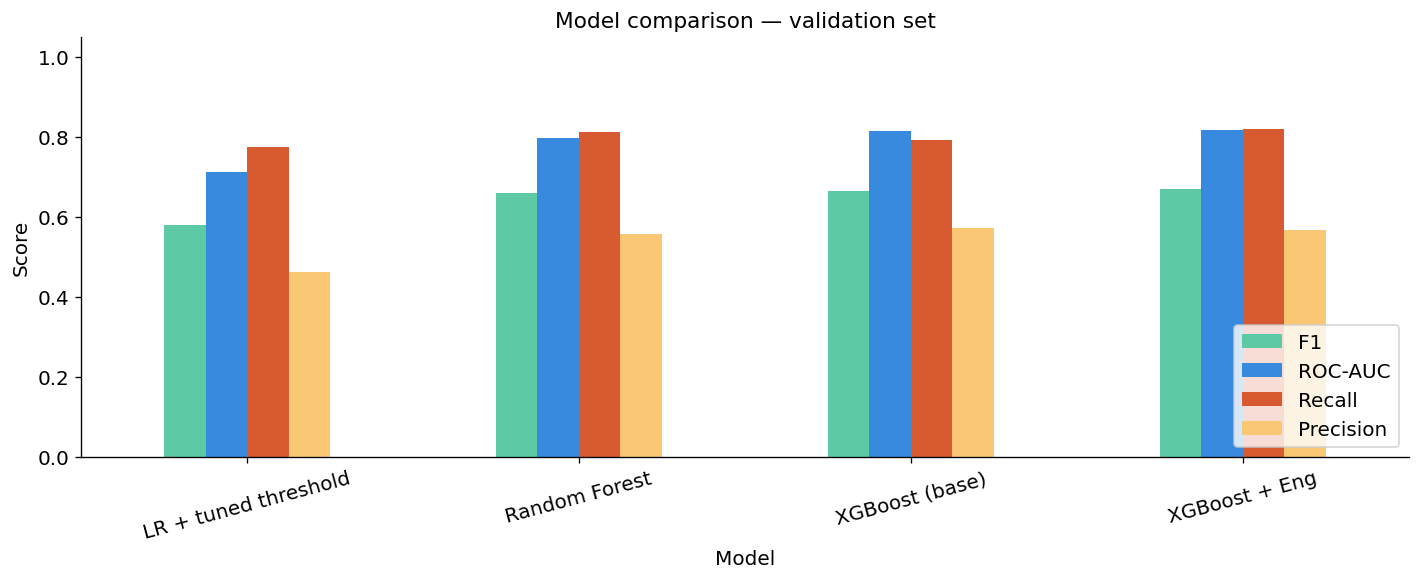

In [ ]:
# Bar chart comparison
fig, ax = plt.subplots(figsize=(12, 5))
results_df[['F1', 'ROC-AUC', 'Recall', 'Precision']].plot(
    kind='bar', ax=ax,
    color=[cfg.COLORS['secondary'], cfg.COLORS['blue'],
           cfg.COLORS['primary'], cfg.COLORS['amber']],
    edgecolor='none'
)
ax.set_title('Model comparison — validation set', fontsize=13)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=15)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(cfg.FIG_DIR / 'model_comparison_bar.png', bbox_inches='tight')
plt.show()

[load_model] Loaded ← c:\Users\adity\OneDrive\Desktop\F1-Pitstop-Predictor\notebooks\..\outputs\models\lr_baseline.joblib


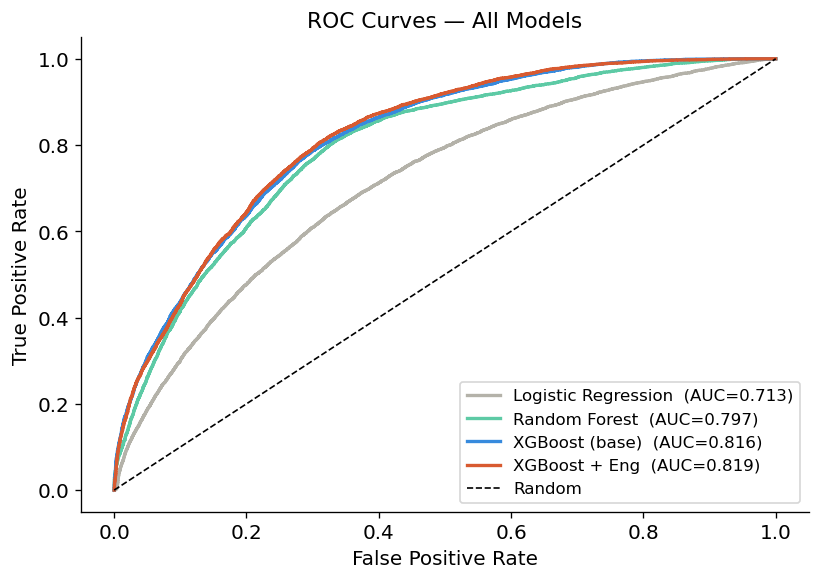

In [ ]:
# ROC overlay
# Reload LR model for probs if needed
from src.train import load_model
try:
    lr_m   = load_model('lr_baseline')
    lr_pbs = lr_m.predict_proba(X_val_s)[:, 1]
except:
    lr_pbs = xgb_probs  # fallback

plot_roc([
    ('Logistic Regression', lr_pbs),
    ('Random Forest',       rf_probs),
    ('XGBoost (base)',      xgb_probs),
    ('XGBoost + Eng',       xgb_eng_probs),
], y_val_e)

In [ ]:
#Model Saving
save_model(rf_model,  'rf_model')
save_model(xgb_model, 'xgb_base')
save_model(xgb_eng,   'xgb_eng')

# Pass these forward to notebook 04
import json
(cfg.OUT_DIR / 'xgb_eng_thresh.json').write_text(
    json.dumps({'threshold': xgb_eng_thresh})
)
print('All models saved. Threshold saved for notebook 04.')

[save_model] Saved → c:\Users\adity\OneDrive\Desktop\F1-Pitstop-Predictor\notebooks\..\outputs\models\rf_model.joblib
[save_model] Saved → c:\Users\adity\OneDrive\Desktop\F1-Pitstop-Predictor\notebooks\..\outputs\models\xgb_base.joblib
[save_model] Saved → c:\Users\adity\OneDrive\Desktop\F1-Pitstop-Predictor\notebooks\..\outputs\models\xgb_eng.joblib
All models saved. Threshold saved for notebook 04.


## 8. Findings

- **Random Forest** beats LR but falls short of XGBoost — tree ensembles handle non-linear tyre degradation curves better.
- **XGBoost** is best on base features.
- **Feature engineering** gives a further F1 boost — `LapsSinceLastPit` and `TyreLife_x_Compound` are the most impactful.
- `scale_pos_weight` is essential — without it XGBoost predicts almost no pits.